# RQ data exploration

Exploratory comparison of the LVVI3 survey and social-media (YouTube) data.

- **Inputs**: `data/LVVI3/lvvi3_survey_en.csv` (main LVVI3 survey table), `data/YouTube/nbt_videos_in_state_owned_lands_cleaned.csv`, and the Clef activity labels at `data/YouTube/clef_labels/youtube_clef_analysis.csv` (long: video x activity) / `youtube_clef_videos_wide.csv` (per-video metadata and engagement counts).
- **Outputs**: none — exploration only; produces no pipeline artifacts.
- **Area types (2026-10-21)**: commercial forests are defined as state land with
  `Admin_level == 'Metsätalous'` (see the *Area type layers* section); the previously
  used subtraction definition (state land minus reserves minus wilderness)
  overestimated commercial forest. Flags stored in the video/trip tables still use
  the old definition.

- **Notes**: the archived Qwen3-VL sub-activity labels (`YouTube_inferenced.csv`, columns `sub_activity`/`type`) were replaced by the Clef labels; the former "new activities" sub-analysis no longer applies because the Clef labels use the LVVI3 activity taxonomy only. Activity renames already applied in the data: `Forest` -> `Nature management`, `Plant` -> `Gardening`.


# Load packages

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import pyogrio

# Read data

## Read LVVI3 data

In [2]:
df_lvvi3 = pd.read_csv('../../data/LVVI3/lvvi3_survey_en.csv')
df_lvvi3 = df_lvvi3.rename(columns={'area_municipality': 'municipality'})

In [3]:
df_lvvi3.gender.unique()

<ArrowStringArray>
['Male', 'Female', 'Other']
Length: 3, dtype: str

## Read YouTube data

In [4]:
def read_geofile(path, **kwargs):
    return gpd.read_file(path, engine="pyogrio", **kwargs)

In [5]:
# Read cleaned data and get the video id list
df_videos = pd.read_csv('../../data/YouTube/nbt_videos_in_state_owned_lands_cleaned.csv')
ls_video_id = df_videos.video_id.tolist()

# Read the geopackage file and keep the cleaned data
gdf_videos = read_geofile('../../data/YouTube/nbt_videos_in_state_owned_lands.gpkg')
gdf_videos = gdf_videos[gdf_videos['video_id'].isin(ls_video_id)]
gdf_videos.shape

(6110, 29)

In [6]:
# Read Clef activity labels (long format: one row per video x activity)
# (built by scripts/RQs_analysis/build_clef_analysis_tables.py)
df_clef = pd.read_csv("../../data/YouTube/clef_labels/youtube_clef_analysis.csv")
# Keep only the cleaned video set
df_clef = df_clef[df_clef['video_id'].isin(ls_video_id)]

# Per-video metadata, engagement counts and area flags from the wide Clef table
df_clef_videos = pd.read_csv("../../data/YouTube/clef_labels/youtube_clef_videos_wide.csv")

df_youtube = df_clef.merge(df_clef_videos[['video_id', 'title', 'description', 'channel_id', 'channel_title',
                                           'comment_count', 'like_count', 'view_count', 'duration',
                                           'datetime', 'year', 'month', 'year_month', 'municipality',
                                           'nature_reserve', 'national_park', 'wilderness_area', 'commercial_forest',
                                           'geometry']], on='video_id', how='left')

# geometry is stored as WKT text in the wide CSV
df_youtube = gpd.GeoDataFrame(df_youtube, geometry=gpd.GeoSeries.from_wkt(df_youtube['geometry']), crs='EPSG:3067')

df_youtube.shape

(11760, 22)

## Read Flickr data

In [7]:
# Read identified Flickr trips
gdf_flickr = gpd.read_file("../../data/Flickr/flickr_trips.gpkg")

gdf_flickr.shape

(1497, 13)

## Read boundaries

In [8]:
# Read Finland boundary shapefile
gdf_finland = read_geofile('../../data/boundaries/Finland_shapefile/Finland_boundaries.shp')
gdf_finland.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [9]:
# Read state-owned lands boundary
gdf_state_lands = read_geofile('../../data/boundaries/MH kiinteistot.gpkg')
gdf_state_lands.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [10]:
# Read state-owned nature reserves boundary
gdf_state_nature_reserves = read_geofile('../../data/boundaries/luonnonsuojelualueet_valtio/LsAlueValtio.shp')
gdf_state_nature_reserves.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [11]:
# Read national parks boundary
gdf_national_parks = read_geofile('../../data/boundaries/finnish_national_parks_syke_2024.gpkg')
gdf_national_parks.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [12]:
# Read wilderness areas boundary
gdf_wilderness = read_geofile('../../data/boundaries/luonnonsuojelualueet_eramaa/LsAlueEramaa.shp')
gdf_wilderness.crs

<Projected CRS: EPSG:3067>
Name: ETRS89 / TM35FIN(E,N)
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Finland - onshore and offshore.
- bounds: (19.08, 58.84, 31.59, 70.09)
Coordinate Operation:
- name: TM35FIN
- method: Transverse Mercator
Datum: European Terrestrial Reference System 1989 ensemble
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [13]:
# Read municipality boundaries
# layers = pyogrio.list_layers('../../data/boundaries/SuomenHallinnollisetKuntajakopohjaisetAluejaot_2026_10k.gpkg')
# print(layers)
gdf_municipality = read_geofile('../../data/boundaries/SuomenHallinnollisetKuntajakopohjaisetAluejaot_2026_10k.gpkg', layer='Kunta')
gdf_municipality = gdf_municipality.rename(columns={'namefin':'municipality'})
gdf_municipality = gdf_municipality[['municipality', 'geometry']]

## Area type layers

The area types used across the project, plotted together:

- **state-owned areas** — all Metsähallitus properties (`MH kiinteistot.gpkg`),
  colored by administrative level (`Admin_level`): `Metsätalous` (Forestry),
  `Luontopalvelut` (Nature Services — statutory protected areas, wilderness,
  conservation programme reservations, other special-value areas), `Kiinteistökehitys`
  (Property development), `Konsernin talous`;
- **commercial forests** — corrected definition: state land administered by
  `Metsätalous` (Forestry). The earlier definition (state-owned land *minus* nature
  reserves *minus* wilderness areas) overestimates commercial forest, because state land
  also contains statutory protected areas, conservation-programme reservations and other
  special-value areas that are neither nature reserves nor wilderness;
- **nature reserves** (`luonnonsuojelualueet_valtio`), **national parks**
  (`finnish_national_parks_syke_2024`), **wilderness areas** (`luonnonsuojelualueet_eramaa`).

In [14]:
# Build (simplified) display layers and compare the old vs corrected commercial forest
state = gdf_state_lands.to_crs(3067)
reserves = gdf_state_nature_reserves.to_crs(3067)
parks = gdf_national_parks.to_crs(3067)
wilderness = gdf_wilderness.to_crs(3067)

state["area_km2"] = state.area / 1e6
commercial_forest = state[state["Admin_level"] == "Metsätalous"]

area_by_admin = (
    state.groupby("Admin_level")["area_km2"].sum().round(0).sort_values(ascending=False)
)
print("State-owned land by administrative level (km2):")
print(area_by_admin.to_string())
print(f"\nTotal state-owned: {state['area_km2'].sum():,.0f} km2")
print(f"Commercial forest, corrected (Admin_level == 'Metsätalous'): "
      f"{commercial_forest['area_km2'].sum():,.0f} km2")

# old definition, approximated on 1 km-simplified geometries (exact overlay is too slow)
TOL = 1000
state_u = state.geometry.simplify(TOL).union_all()
reserves_u = reserves.geometry.simplify(TOL).union_all()
wilderness_u = wilderness.geometry.simplify(TOL).union_all()
old_cf = (
    gpd.GeoDataFrame(geometry=[state_u], crs=state.crs)
    .overlay(gpd.GeoDataFrame(geometry=[reserves_u], crs=reserves.crs), how="difference")
    .overlay(gpd.GeoDataFrame(geometry=[wilderness_u], crs=wilderness.crs), how="difference")
)
print(f"Commercial forest, OLD definition (state - reserves - wilderness, approx): "
      f"{old_cf.area.sum() / 1e6:,.0f} km2")

State-owned land by administrative level (km2):
Admin_level
Metsätalous          53743.0
Luontopalvelut       45991.0
Kiinteistökehitys    26381.0
Konsernin talous         0.0

Total state-owned: 126,115 km2
Commercial forest, corrected (Admin_level == 'Metsätalous'): 53,743 km2


/projappl/project_2006782/leyixu/cpu-env/lib/python3.12/site-packages/geopandas/geodataframe.py:2675: UserWarning: `keep_geom_type=True` in overlay resulted in 37216 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  return geopandas.overlay(


Commercial forest, OLD definition (state - reserves - wilderness, approx): 86,293 km2


/projappl/project_2006782/leyixu/cpu-env/lib/python3.12/site-packages/geopandas/geodataframe.py:2675: UserWarning: `keep_geom_type=True` in overlay resulted in 37596 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  return geopandas.overlay(


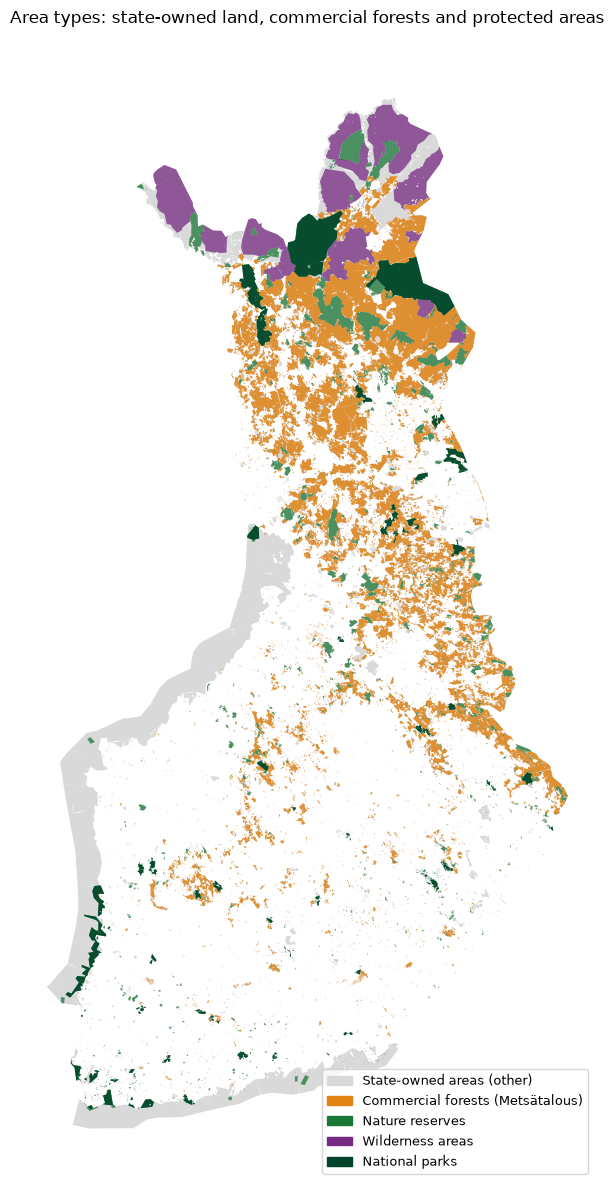

In [15]:
import matplotlib.patches as mpatches

TOL = 1000  # metres; display-only simplification

fig, ax = plt.subplots(figsize=(9, 12))

gpd.GeoDataFrame(geometry=[state_u], crs=state.crs).plot(
    ax=ax, color="#d9d9d9", edgecolor="none")
gpd.GeoDataFrame(
    geometry=[commercial_forest.geometry.simplify(TOL).union_all()], crs=state.crs
).plot(ax=ax, color="#e08214", edgecolor="none", alpha=0.85)
gpd.GeoDataFrame(geometry=[reserves_u], crs=reserves.crs).plot(
    ax=ax, color="#1b7837", edgecolor="none", alpha=0.75)
gpd.GeoDataFrame(geometry=[wilderness_u], crs=wilderness.crs).plot(
    ax=ax, color="#762a83", edgecolor="none", alpha=0.75)
gpd.GeoDataFrame(geometry=[parks.geometry.simplify(TOL).union_all()], crs=parks.crs).plot(
    ax=ax, color="#004529", edgecolor="none", alpha=0.9)

ax.legend(handles=[
    mpatches.Patch(color="#d9d9d9", label="State-owned areas (other)"),
    mpatches.Patch(color="#e08214", label="Commercial forests (Metsätalous)"),
    mpatches.Patch(color="#1b7837", label="Nature reserves"),
    mpatches.Patch(color="#762a83", label="Wilderness areas"),
    mpatches.Patch(color="#004529", label="National parks"),
], loc="lower right", fontsize=9)
ax.set_title("Area types: state-owned land, commercial forests and protected areas")
ax.set_axis_off()
plt.tight_layout()
plt.show()

Note: national parks largely overlap the nature-reserve layer, and the nature-reserve /
wilderness layers overlap the `Luontopalvelut` state land — the layers are shown on top of
each other rather than subtracted. The corrected commercial-forest layer
(`Admin_level == 'Metsätalous'`) has only negligible overlap with the protected layers
(boundary effects of a few hundred km² in total).

## Create channel-level activity dataframe

In [16]:
# Aggregate activities per channel into a single list
df_channel_agg = (
    df_youtube.groupby("channel_id")["activity"]
    .apply(lambda x: sorted(set(x)))
    .reset_index()
)

In [17]:
df_channel_agg.head()

,channel_id,activity
0,UC--_RQv4KXF_MlRrs5XQI6Q,"[Guided tour, Walking]"
1,UC--klkcCXADczMaxwUJkNgw,"[Sledding, Travelling or staying in a caravan ..."
2,UC-0IOln7zRjX34HiNyZ2WFw,"[Outdoor activities with children, Walking]"
3,UC-0qvruAkcupf1uBAaiIkOw,"[Sledding, Walking]"
4,UC-1kd43HVFkstMtcAoprWHg,[Nature observation]


# Activity count

## Structural activity

In [18]:
# Get counts
youtube_counts = df_youtube['structural_activity'].value_counts()
lvvi3_counts = df_lvvi3['structural_activity'].value_counts()

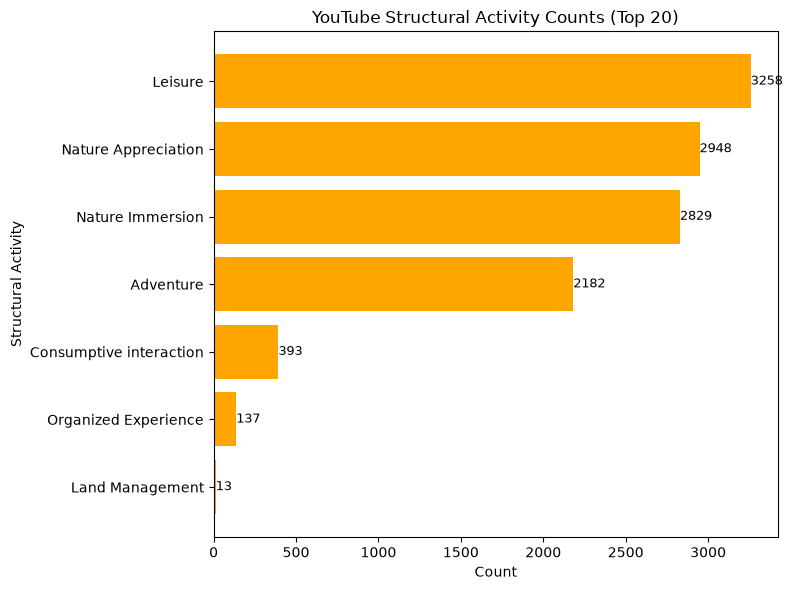

In [19]:
# Get top 20 activities
activity_counts = youtube_counts[:20]
activity_counts = activity_counts[::-1]

# Plot horizontal bars
plt.figure(figsize=(8, 6))
bars = plt.barh(activity_counts.index, activity_counts.values, color='orange')
plt.xlabel('Count')
plt.ylabel('Structural Activity')
plt.title('YouTube Structural Activity Counts (Top 20)')

# Add value labels next to bars
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2, str(width),
             va='center', ha='left', fontsize=9)

plt.tight_layout()
plt.show()

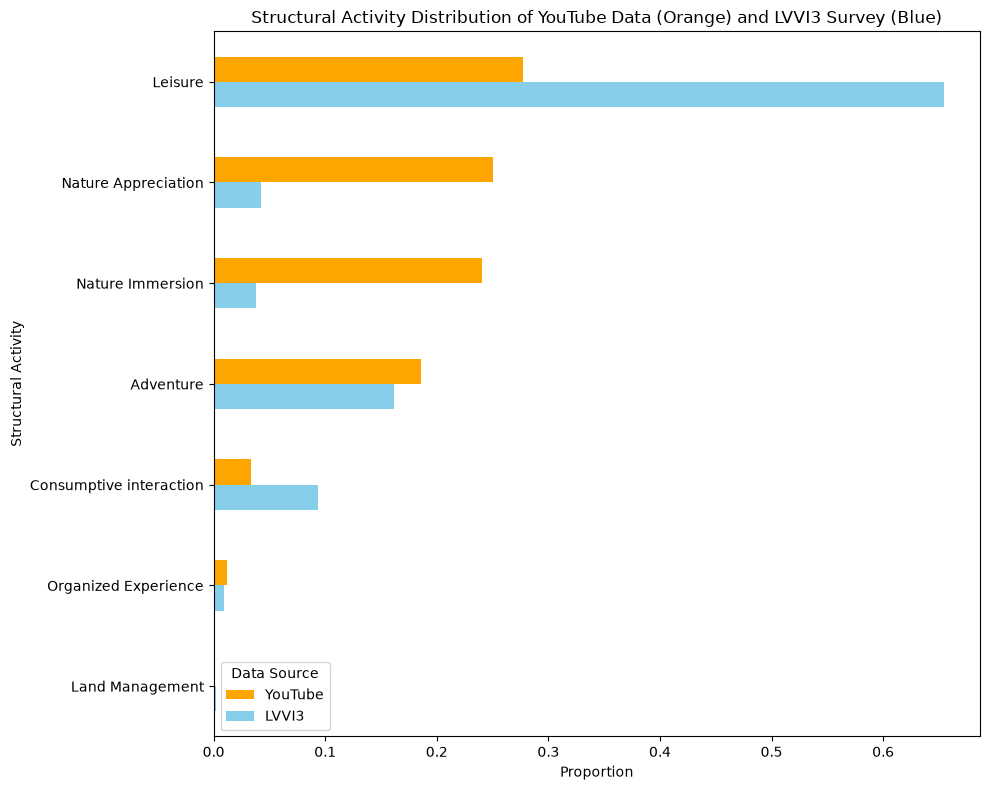

In [20]:
# Combine counts
combined = pd.DataFrame({
    'YouTube': youtube_counts,
    'LVVI3': lvvi3_counts,
}).fillna(0)

# Normalize
combined = combined / combined.sum()

# Sort by YouTube
combined = combined.sort_values('YouTube', ascending=True).tail(20)

# Reorder columns so YouTube is ABOVE
combined = combined[['LVVI3', 'YouTube']]

# Plot
ax = combined.plot(
    kind='barh',
    figsize=(10, 8),
    color=['skyblue', 'orange']
)

plt.title('Structural Activity Distribution of YouTube Data (Orange) and LVVI3 Survey (Blue)')
plt.xlabel('Proportion')
plt.ylabel('Structural Activity')

# 👉 Fix legend order
handles, labels = ax.get_legend_handles_labels()
order = [1, 0]

plt.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    title='Data Source'
)

plt.tight_layout()
plt.show()

In [21]:
# Convert to ranks
youtube_rank = youtube_counts.rank(ascending=False, method='min')
lvvi3_rank = lvvi3_counts.rank(ascending=False, method='min')
lvvi3_rank = lvvi3_counts.rank(ascending=False, method='min')

# Combine
rank_df = pd.DataFrame({
    'YouTube': youtube_rank,
    'LVVI3': lvvi3_rank
}).dropna()

# Keep top N (based on YouTube for consistency)
rank_df = rank_df.sort_values('YouTube').head(50)

Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.


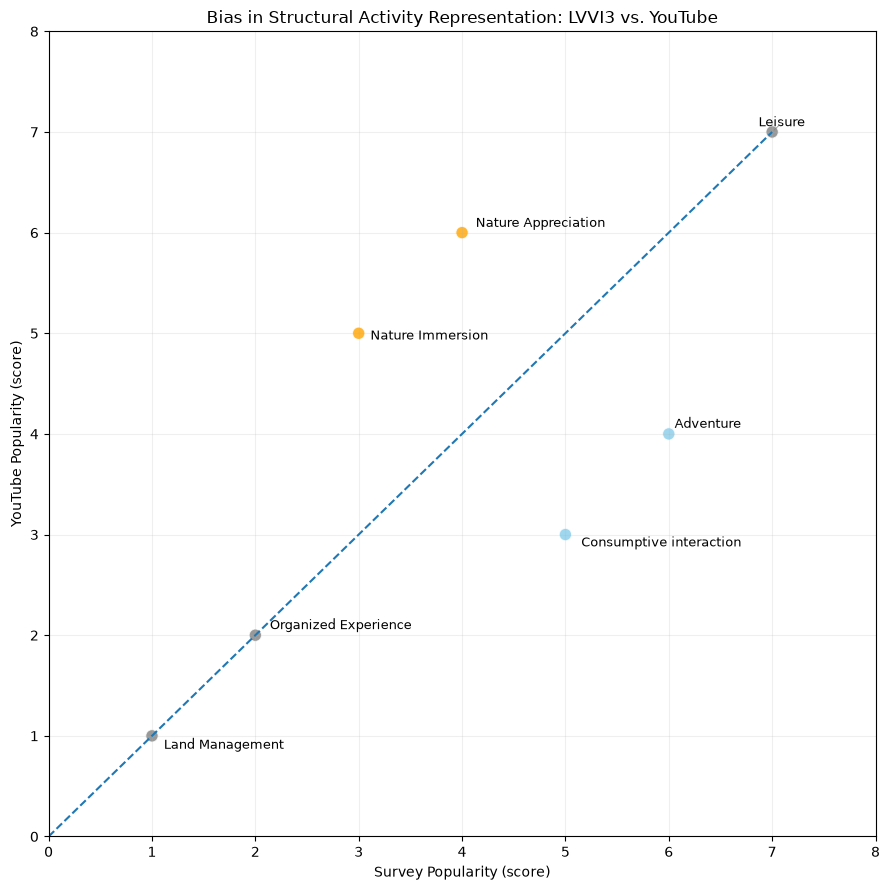

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from adjustText import adjust_text


plt.figure(figsize=(9, 9))

# --- Convert rank → score (higher = more popular) ---
max_rank = int(rank_df[['LVVI3', 'YouTube']].max().max())

rank_df['LVVI3_score'] = max_rank + 1 - rank_df['LVVI3']
rank_df['YouTube_score'] = max_rank + 1 - rank_df['YouTube']

# --- Compute difference ---
rank_df['diff'] = rank_df['YouTube_score'] - rank_df['LVVI3_score']

# --- Color by bias ---
colors = np.where(rank_df['diff'] > 0, 'orange',   # more on YouTube
         np.where(rank_df['diff'] < 0, 'skyblue',  # more in Survey
                  'gray'))

# --- Scatter ---
plt.scatter(
    rank_df['LVVI3_score'],
    rank_df['YouTube_score'],
    c=colors,
    alpha=0.8,
    s=80,
    edgecolor='white',
    linewidth=0.8
)

# --- Diagonal reference line ---
max_score = rank_df[['LVVI3_score', 'YouTube_score']].max().max()
plt.plot([0, max_score], [0, max_score], linestyle='--')


texts = []

for activity in rank_df.index:
    x = rank_df.loc[activity, 'LVVI3_score']
    y = rank_df.loc[activity, 'YouTube_score']
    
    texts.append(
        plt.text(x, y, activity, fontsize=9)
    )

adjust_text(
    texts,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
    expand_points=(1.2, 1.2)
)

# Set the axis limits to start at 0
plt.xlim(0, max_score + 1)
plt.ylim(0, max_score + 1)

# --- Labels & title ---
plt.xlabel('Survey Popularity (score)')
plt.ylabel('YouTube Popularity (score)')
plt.title('Bias in Structural Activity Representation: LVVI3 vs. YouTube')

# --- Clean look ---
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

## Activity

In [23]:
# Get counts
youtube_counts = df_youtube['activity'].value_counts()
flickr_counts = gdf_flickr['activity'].value_counts()
lvvi3_counts = df_lvvi3['activity'].value_counts()

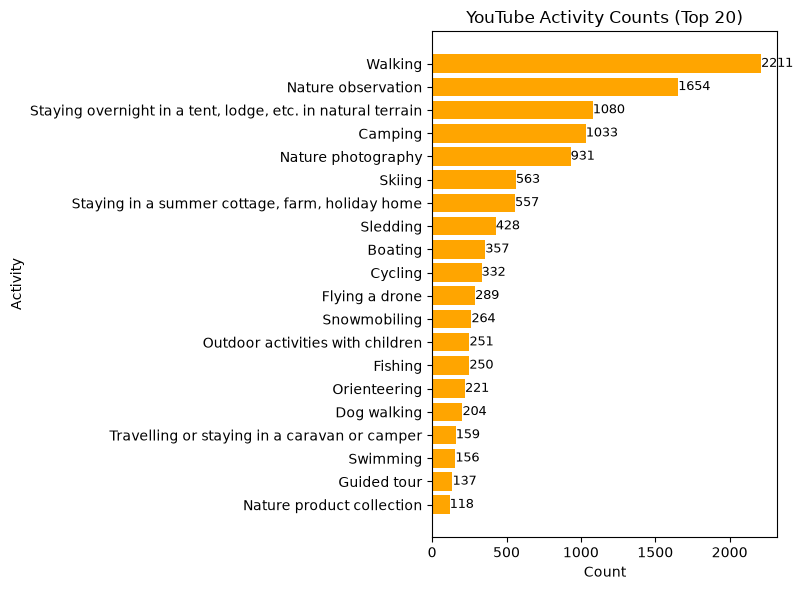

In [24]:
# Get top 20 activities
activity_counts = youtube_counts[:20]
activity_counts = activity_counts[::-1]

# Plot horizontal bars
plt.figure(figsize=(8, 6))
bars = plt.barh(activity_counts.index, activity_counts.values, color='orange')
plt.xlabel('Count')
plt.ylabel('Activity')
plt.title('YouTube Activity Counts (Top 20)')

# Add value labels next to bars
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2, str(width),
             va='center', ha='left', fontsize=9)

plt.tight_layout()
plt.show()

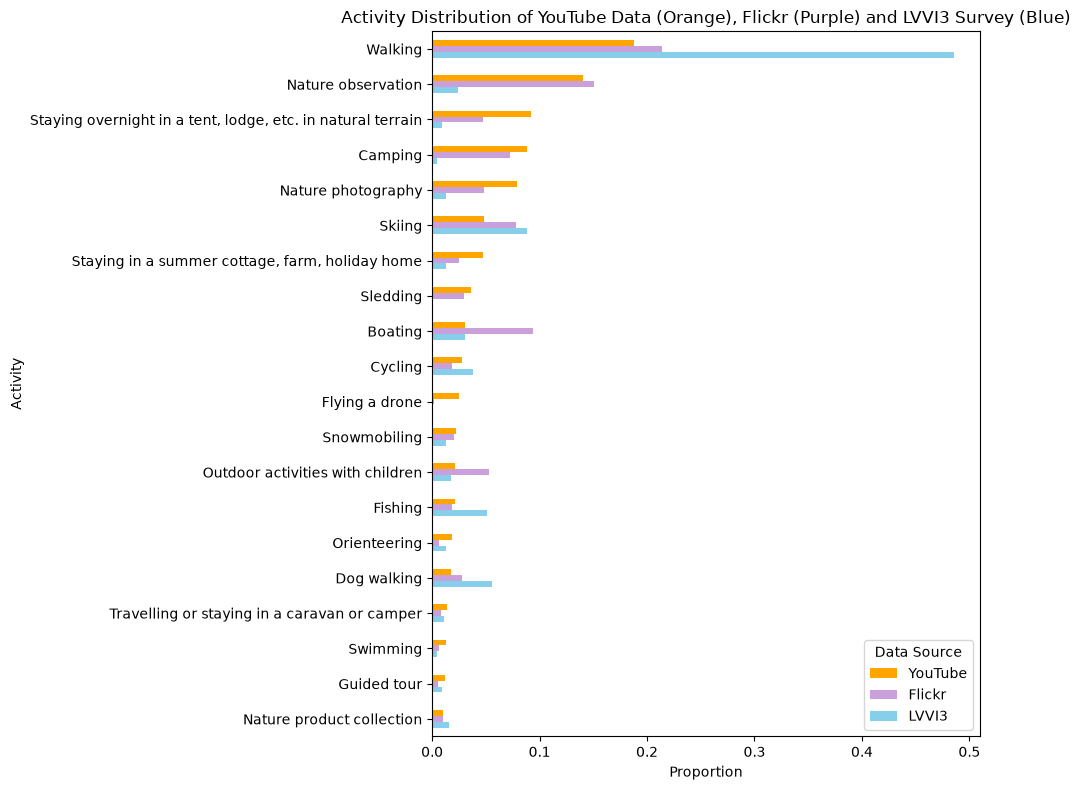

In [25]:
# Combine counts
combined = pd.DataFrame({
    'YouTube': youtube_counts,
    'Flickr': flickr_counts,
    'LVVI3': lvvi3_counts,
}).fillna(0)

# Normalize
combined = combined / combined.sum()

# Sort by YouTube
combined = combined.sort_values('YouTube', ascending=True).tail(20)

# Reorder columns so YouTube is ABOVE
combined = combined[['LVVI3', 'Flickr', 'YouTube']]

# Plot
ax = combined.plot(
    kind='barh',
    figsize=(10, 8),
    color=['skyblue', '#C9A0DC', 'orange']
)

plt.title('Activity Distribution of YouTube Data (Orange), Flickr (Purple) and LVVI3 Survey (Blue)')
plt.xlabel('Proportion')
plt.ylabel('Activity')

# --- legend ---
handles, labels = ax.get_legend_handles_labels()
order = [2, 1, 0]

plt.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    title='Data Source'
)

plt.tight_layout()
plt.show()

In [26]:
# Convert to ranks
youtube_rank = youtube_counts.rank(ascending=False, method='min')
flickr_rank = flickr_counts.rank(ascending=False, method='min')
lvvi3_rank = lvvi3_counts.rank(ascending=False, method='min')

# Combine
rank_df = pd.DataFrame({
    'YouTube': youtube_rank,
    'Flickr': flickr_rank,
    'LVVI3': lvvi3_rank
}).dropna()

# Keep top N (based on YouTube for consistency)
rank_df = rank_df.sort_values('YouTube').head(50)

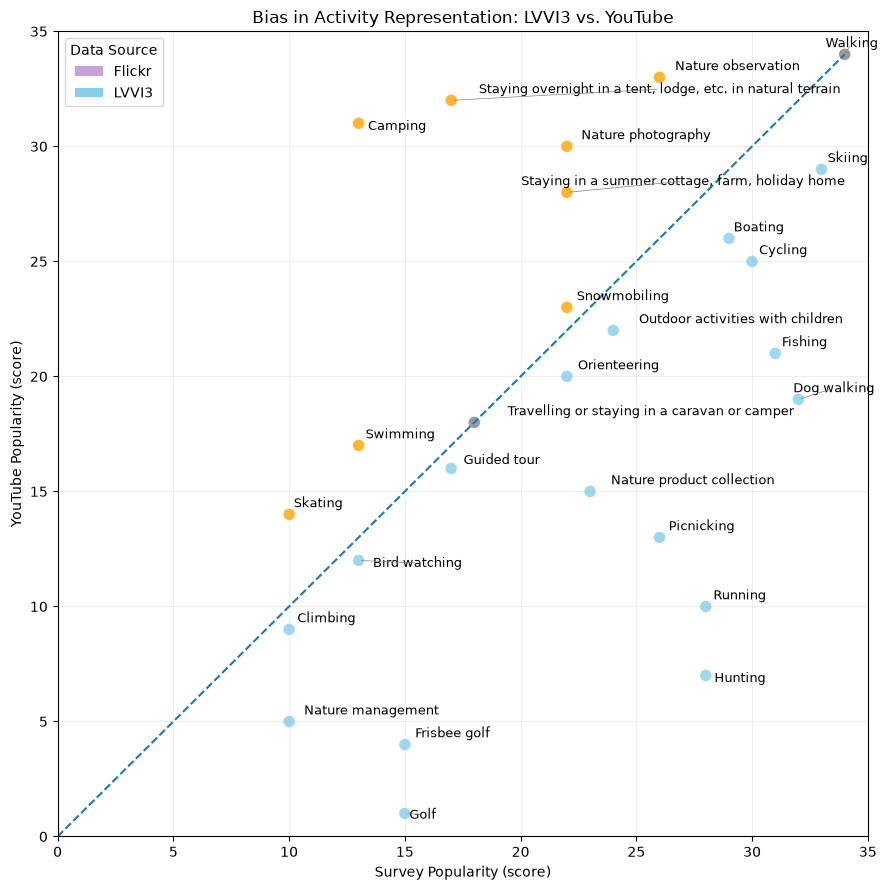

In [27]:
import matplotlib.pyplot as plt
import numpy as np
from adjustText import adjust_text


plt.figure(figsize=(9, 9))

# --- Convert rank → score (higher = more popular) ---
max_rank = int(rank_df[['LVVI3', 'YouTube']].max().max())

rank_df['LVVI3_score'] = max_rank + 1 - rank_df['LVVI3']
rank_df['YouTube_score'] = max_rank + 1 - rank_df['YouTube']

# --- Compute difference ---
rank_df['diff'] = rank_df['YouTube_score'] - rank_df['LVVI3_score']

# --- Color by bias ---
colors = np.where(rank_df['diff'] > 0, 'orange',   # more on YouTube
         np.where(rank_df['diff'] < 0, 'skyblue',  # more in Survey
                  'gray'))

# --- Scatter ---
plt.scatter(
    rank_df['LVVI3_score'],
    rank_df['YouTube_score'],
    c=colors,
    alpha=0.8,
    s=80,
    edgecolor='white',
    linewidth=0.8
)

# --- Diagonal reference line ---
max_score = rank_df[['LVVI3_score', 'YouTube_score']].max().max()
plt.plot([0, max_score], [0, max_score], linestyle='--')


texts = []

for activity in rank_df.index:
    x = rank_df.loc[activity, 'LVVI3_score']
    y = rank_df.loc[activity, 'YouTube_score']
    
    texts.append(
        plt.text(x, y, activity, fontsize=9)
    )

adjust_text(
    texts,
    arrowprops=dict(arrowstyle='-', color='gray', lw=0.5),
    expand_points=(1.2, 1.2)
)

# Set the axis limits to start at 0
plt.xlim(0, max_score + 1)
plt.ylim(0, max_score + 1)

# --- Labels & title ---
plt.xlabel('Survey Popularity (score)')
plt.ylabel('YouTube Popularity (score)')
plt.title('Bias in Activity Representation: LVVI3 vs. YouTube')

# --- legend ---
handles, labels = ax.get_legend_handles_labels()
order = [1, 0]

plt.legend(
    [handles[i] for i in order],
    [labels[i] for i in order],
    title='Data Source'
)

# --- Clean look ---
plt.grid(alpha=0.2)
plt.tight_layout()

plt.show()

# Activity correlation

In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Pivot to create binary matrix: rows = video_id, columns = activities
activity_matrix = df_youtube[df_youtube['activity'].isin(activity_counts.index)].pivot_table(
    index='video_id',
    columns='activity',
    aggfunc='size',
    fill_value=0
)

# Convert counts >1 to 1 (presence/absence)
activity_matrix = (activity_matrix > 0).astype(int)

activity_corr = activity_matrix.corr()

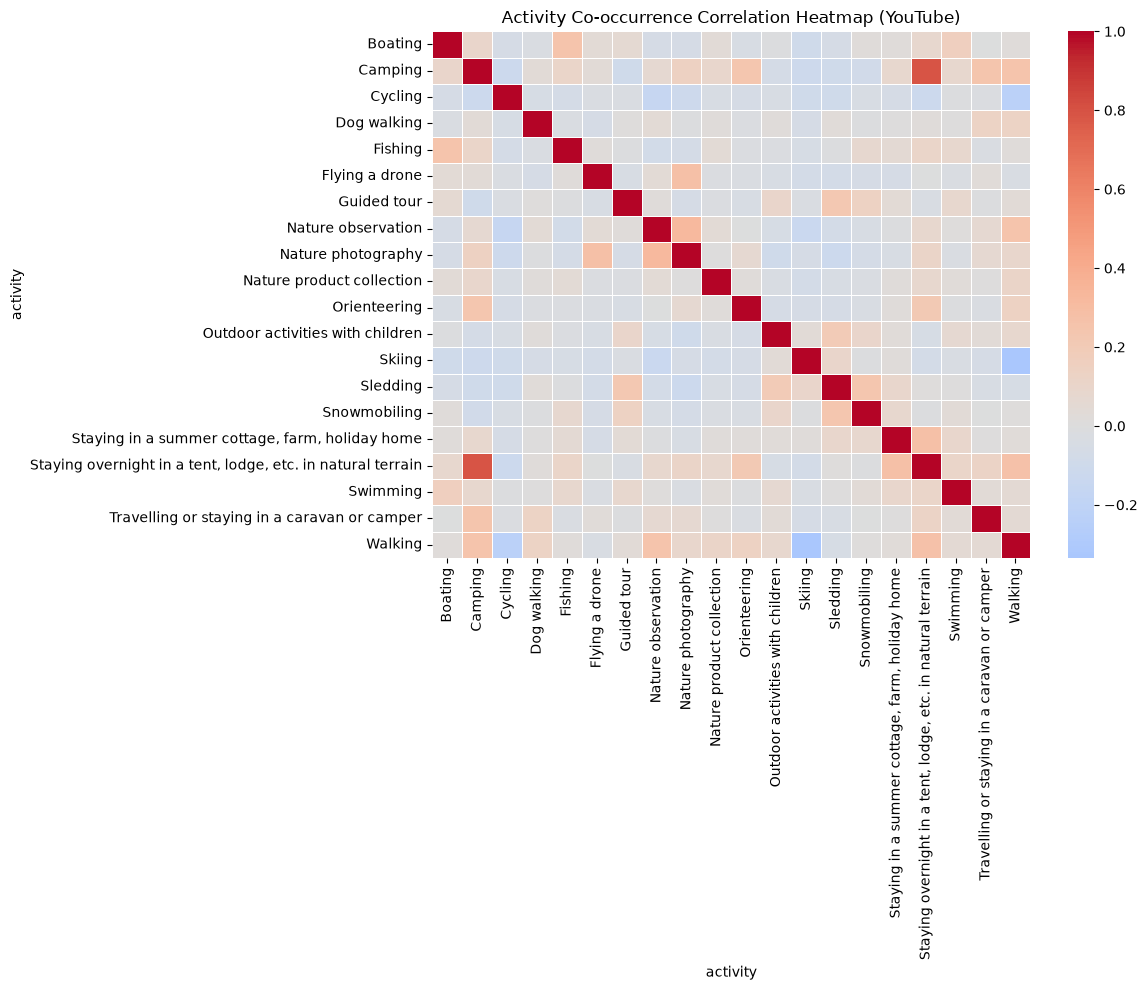

In [29]:
plt.figure(figsize=(12, 10))
sns.heatmap(
    activity_corr,
    cmap='coolwarm',
    center=0,
    linewidths=0.5,
    annot=False
)
plt.title('Activity Co-occurrence Correlation Heatmap (YouTube)')
plt.tight_layout()
plt.show()

# Spatial distribution

In [30]:
# Example structure
lvvi3_map = df_lvvi3.groupby('municipality')['activity'].value_counts(normalize=True)
youtube_map = df_youtube.groupby('municipality')['activity'].value_counts(normalize=True)

In [31]:
def plot_activity_map(
    activity,
    df_lvvi3,
    df_youtube,
    gdf_municipality,
    activity_col="activity",
    muni_col="municipality"
):
    import matplotlib.pyplot as plt

    # --- Aggregate activity per municipality ---
    lvvi3_map = (
        df_lvvi3[df_lvvi3[activity_col] == activity]
        .groupby(muni_col)
        .size()
    )

    youtube_map = (
        df_youtube[df_youtube[activity_col] == activity]
        .groupby(muni_col)
        .size()
    )

    # Normalize
    if lvvi3_map.sum() != 0:
        lvvi3_map = lvvi3_map / lvvi3_map.sum()
    if youtube_map.sum() != 0:
        youtube_map = youtube_map / youtube_map.sum()

    # --- Merge with spatial data ---
    gdf_map = gdf_municipality.merge(
        lvvi3_map.rename("lvvi3"),
        on=muni_col,
        how="left"
    )

    gdf_map = gdf_map.merge(
        youtube_map.rename("youtube"),
        on=muni_col,
        how="left"
    )

    gdf_map = gdf_map.fillna(0)

    # Compute spatial bias
    gdf_map["diff"] = gdf_map["youtube"] - gdf_map["lvvi3"]

    # --- Plot ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    # Survey
    gdf_map.plot(
        column="lvvi3",
        cmap="Blues",
        linewidth=0.1,
        ax=axes[0],
        legend=True
    )
    gdf_municipality.boundary.plot(ax=axes[0], linewidth=0.5, edgecolor="lightgrey")
    axes[0].set_title("LVVI3")
    axes[0].axis("off")

    # YouTube
    gdf_map.plot(
        column="youtube",
        cmap="Oranges",
        linewidth=0.1,
        ax=axes[1],
        legend=True
    )
    gdf_municipality.boundary.plot(ax=axes[1], linewidth=0.5, edgecolor="lightgrey")
    axes[1].set_title("YouTube")
    axes[1].axis("off")

    # Difference
    gdf_map.plot(
        column="diff",
        cmap="coolwarm",
        linewidth=0.1,
        ax=axes[2],
        legend=True
    )
    gdf_municipality.boundary.plot(ax=axes[2], linewidth=0.5, edgecolor="lightgrey")
    axes[2].set_title("Bias (YouTube - Survey)")
    axes[2].axis("off")

    plt.suptitle(f"Spatial Distribution of {activity}", fontsize=16)
    plt.tight_layout()
    plt.show()

    return gdf_map  # optional: return for further analysis

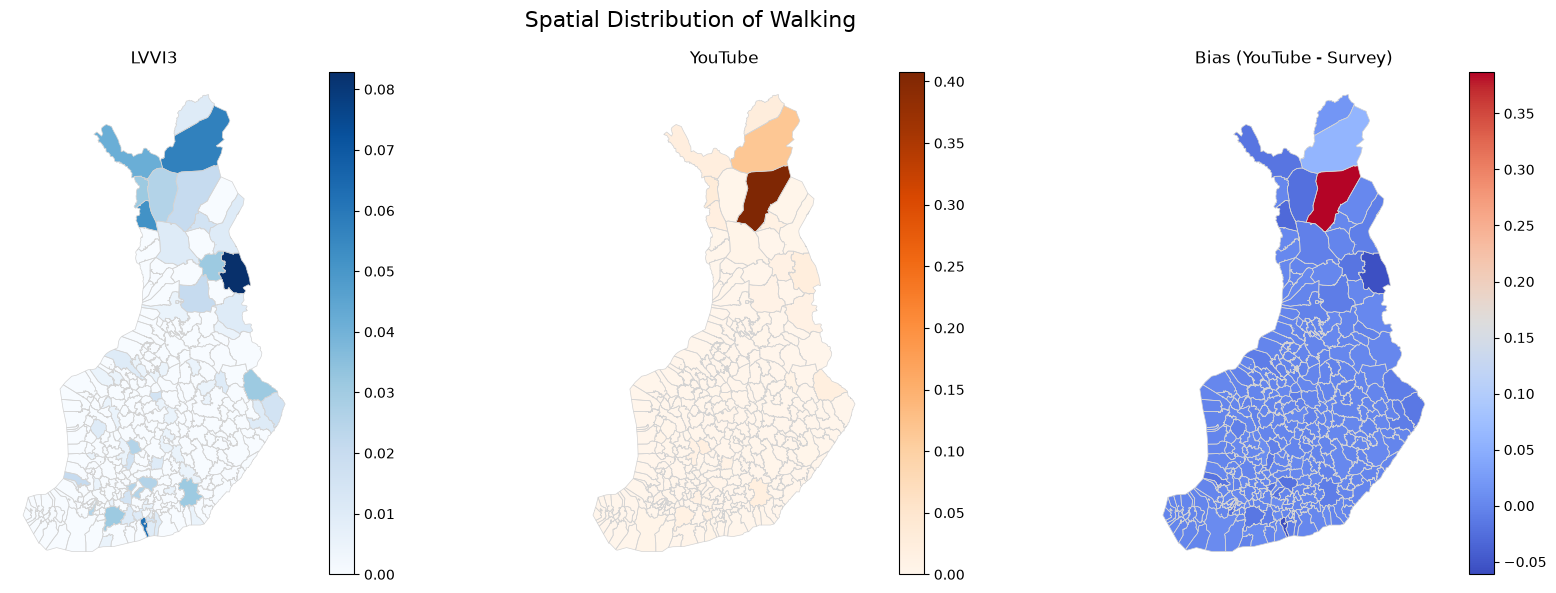

,municipality,geometry,lvvi3,youtube,diff
0,Parainen,"MULTIPOLYGON (((222641.081 6606081.869, 209305...",0.000000,0.006332,0.006332
1,Outokumpu,"MULTIPOLYGON (((617807.354 6956270.87, 617128....",0.000000,0.000452,0.000452
2,Rauma,"MULTIPOLYGON (((211671.977 6774130.131, 211282...",0.020725,0.000000,-0.020725
3,Alajärvi,"MULTIPOLYGON (((333911.129 6968504.391, 333550...",0.000000,0.000000,0.000000
4,Posio,"MULTIPOLYGON (((569086.721 7303600.875, 568502...",0.031088,0.013569,-0.017520
...,...,...,...,...,...
303,Teuva,"MULTIPOLYGON (((219000.267 6933062.951, 218989...",0.000000,0.000000,0.000000
304,Hankasalmi,"MULTIPOLYGON (((465203.294 6898115.267, 465109...",0.000000,0.000000,0.000000
305,Soini,"MULTIPOLYGON (((365541.96 6984316.807, 365525....",0.000000,0.000000,0.000000
306,Kauhava,"MULTIPOLYGON (((321659.111 7021930.732, 321605...",0.000000,0.000000,0.000000


In [32]:
plot_activity_map(
    activity="Walking",
    df_lvvi3=df_lvvi3,
    df_youtube=df_youtube,
    gdf_municipality=gdf_municipality
)

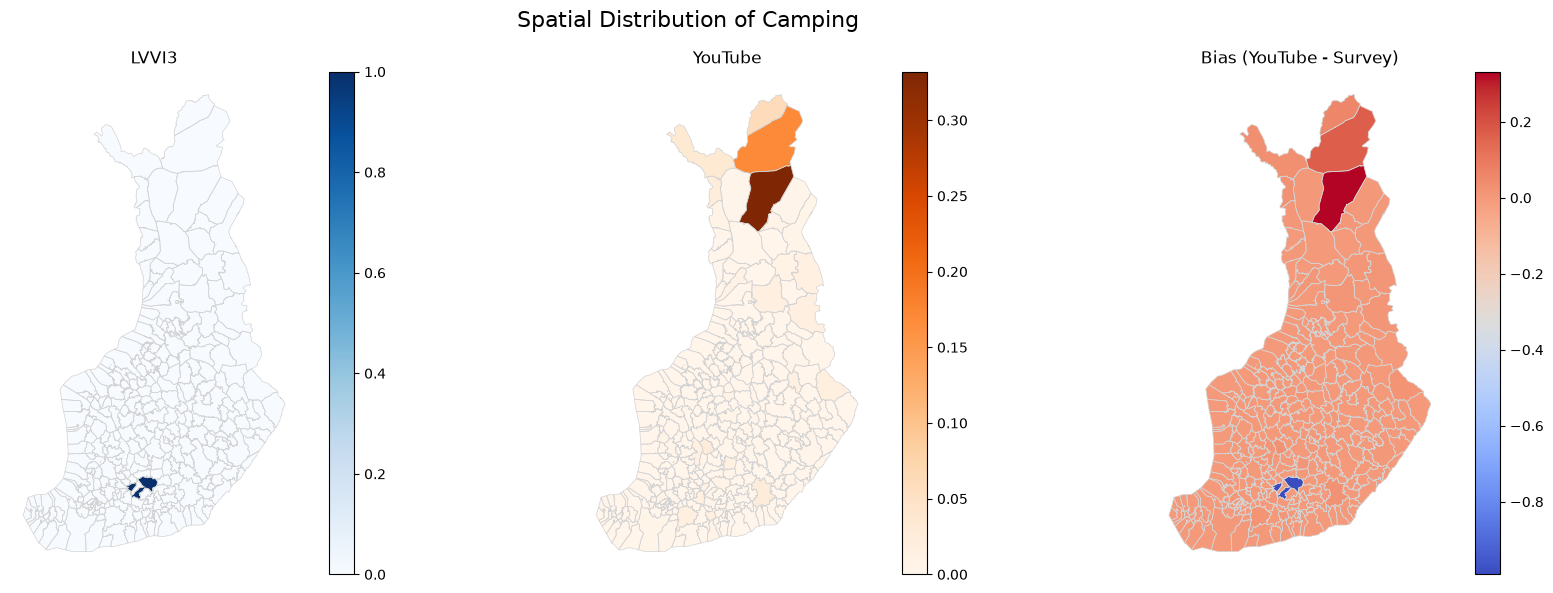

,municipality,geometry,lvvi3,youtube,diff
0,Parainen,"MULTIPOLYGON (((222641.081 6606081.869, 209305...",0.0,0.004840,0.004840
1,Outokumpu,"MULTIPOLYGON (((617807.354 6956270.87, 617128....",0.0,0.000968,0.000968
2,Rauma,"MULTIPOLYGON (((211671.977 6774130.131, 211282...",0.0,0.000000,0.000000
3,Alajärvi,"MULTIPOLYGON (((333911.129 6968504.391, 333550...",0.0,0.000000,0.000000
4,Posio,"MULTIPOLYGON (((569086.721 7303600.875, 568502...",0.0,0.006776,0.006776
...,...,...,...,...,...
303,Teuva,"MULTIPOLYGON (((219000.267 6933062.951, 218989...",0.0,0.000000,0.000000
304,Hankasalmi,"MULTIPOLYGON (((465203.294 6898115.267, 465109...",0.0,0.000000,0.000000
305,Soini,"MULTIPOLYGON (((365541.96 6984316.807, 365525....",0.0,0.000000,0.000000
306,Kauhava,"MULTIPOLYGON (((321659.111 7021930.732, 321605...",0.0,0.000000,0.000000


In [33]:
plot_activity_map(
    activity="Camping",
    df_lvvi3=df_lvvi3,
    df_youtube=df_youtube,
    gdf_municipality=gdf_municipality
)

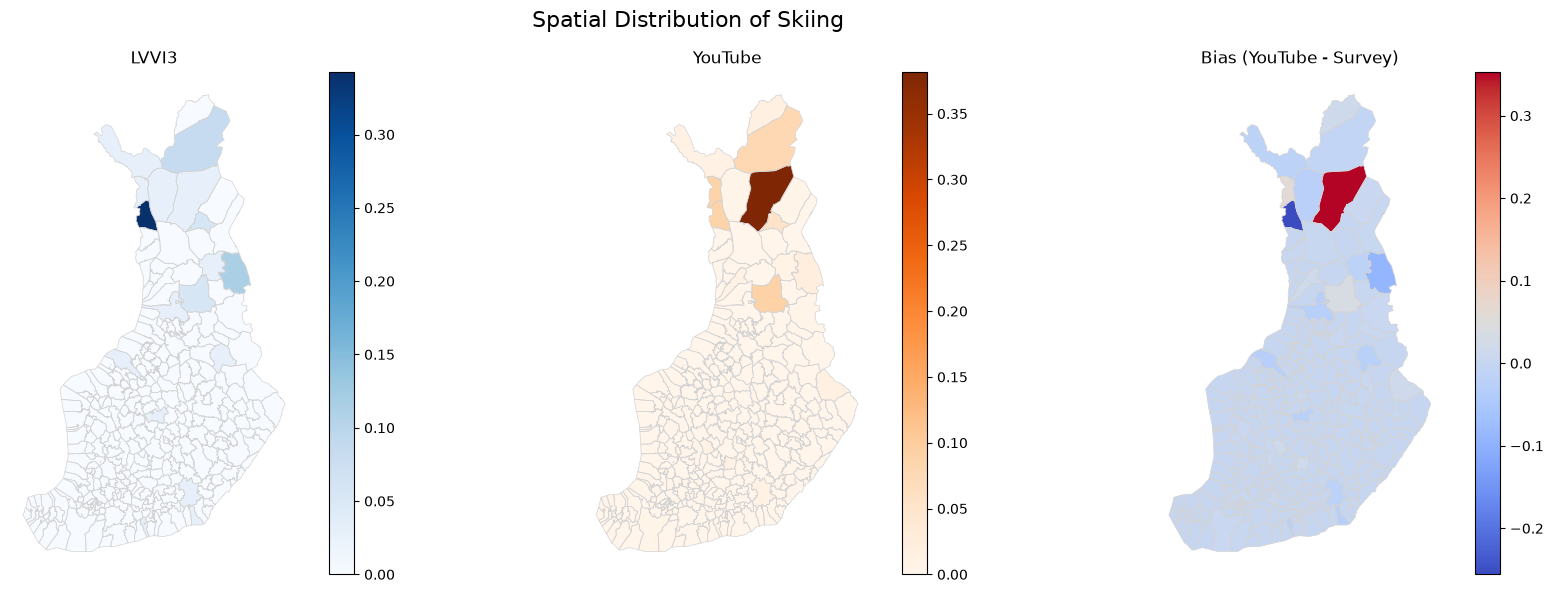

,municipality,geometry,lvvi3,youtube,diff
0,Parainen,"MULTIPOLYGON (((222641.081 6606081.869, 209305...",0.000000,0.005329,0.005329
1,Outokumpu,"MULTIPOLYGON (((617807.354 6956270.87, 617128....",0.000000,0.000000,0.000000
2,Rauma,"MULTIPOLYGON (((211671.977 6774130.131, 211282...",0.000000,0.000000,0.000000
3,Alajärvi,"MULTIPOLYGON (((333911.129 6968504.391, 333550...",0.000000,0.000000,0.000000
4,Posio,"MULTIPOLYGON (((569086.721 7303600.875, 568502...",0.028571,0.008881,-0.019690
...,...,...,...,...,...
303,Teuva,"MULTIPOLYGON (((219000.267 6933062.951, 218989...",0.000000,0.000000,0.000000
304,Hankasalmi,"MULTIPOLYGON (((465203.294 6898115.267, 465109...",0.000000,0.000000,0.000000
305,Soini,"MULTIPOLYGON (((365541.96 6984316.807, 365525....",0.000000,0.000000,0.000000
306,Kauhava,"MULTIPOLYGON (((321659.111 7021930.732, 321605...",0.000000,0.000000,0.000000


In [34]:
plot_activity_map(
    activity="Skiing",
    df_lvvi3=df_lvvi3,
    df_youtube=df_youtube,
    gdf_municipality=gdf_municipality
)

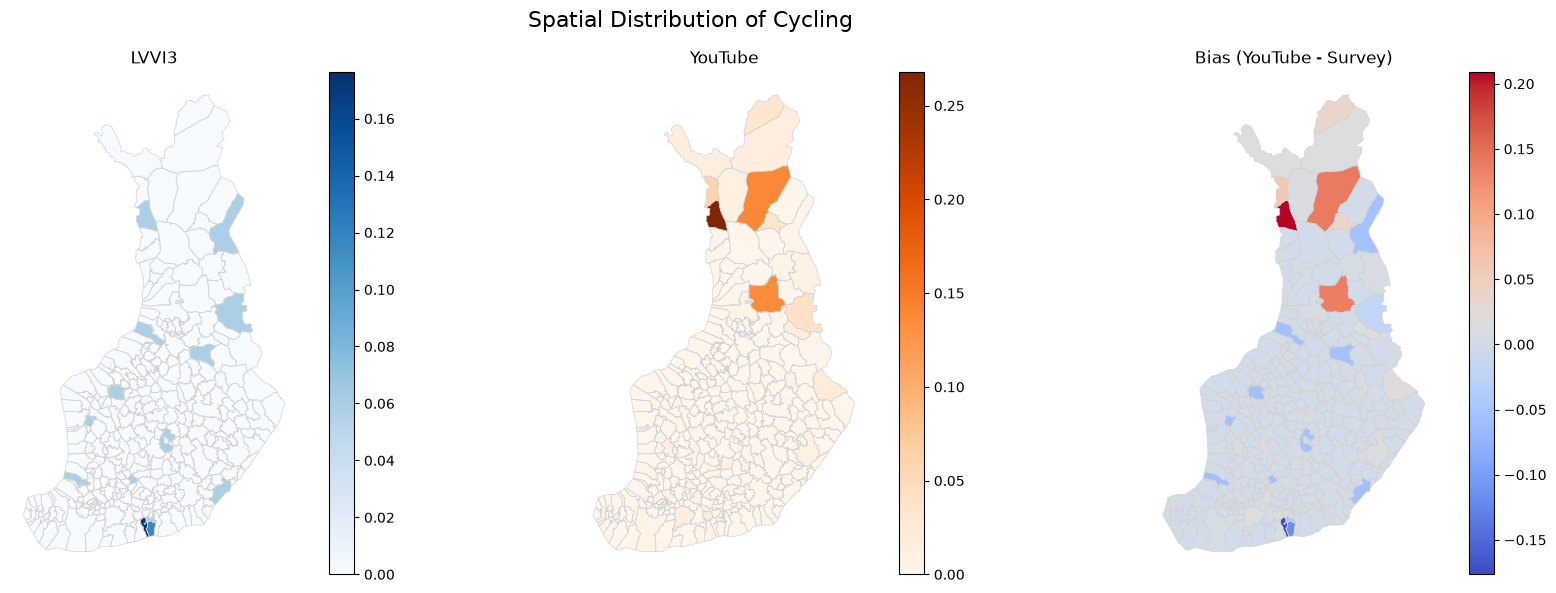

,municipality,geometry,lvvi3,youtube,diff
0,Parainen,"MULTIPOLYGON (((222641.081 6606081.869, 209305...",0.000000,0.006024,0.006024
1,Outokumpu,"MULTIPOLYGON (((617807.354 6956270.87, 617128....",0.000000,0.000000,0.000000
2,Rauma,"MULTIPOLYGON (((211671.977 6774130.131, 211282...",0.058824,0.000000,-0.058824
3,Alajärvi,"MULTIPOLYGON (((333911.129 6968504.391, 333550...",0.000000,0.000000,0.000000
4,Posio,"MULTIPOLYGON (((569086.721 7303600.875, 568502...",0.000000,0.006024,0.006024
...,...,...,...,...,...
303,Teuva,"MULTIPOLYGON (((219000.267 6933062.951, 218989...",0.058824,0.000000,-0.058824
304,Hankasalmi,"MULTIPOLYGON (((465203.294 6898115.267, 465109...",0.000000,0.000000,0.000000
305,Soini,"MULTIPOLYGON (((365541.96 6984316.807, 365525....",0.000000,0.000000,0.000000
306,Kauhava,"MULTIPOLYGON (((321659.111 7021930.732, 321605...",0.058824,0.000000,-0.058824


In [35]:
plot_activity_map(
    activity="Cycling",
    df_lvvi3=df_lvvi3,
    df_youtube=df_youtube,
    gdf_municipality=gdf_municipality
)

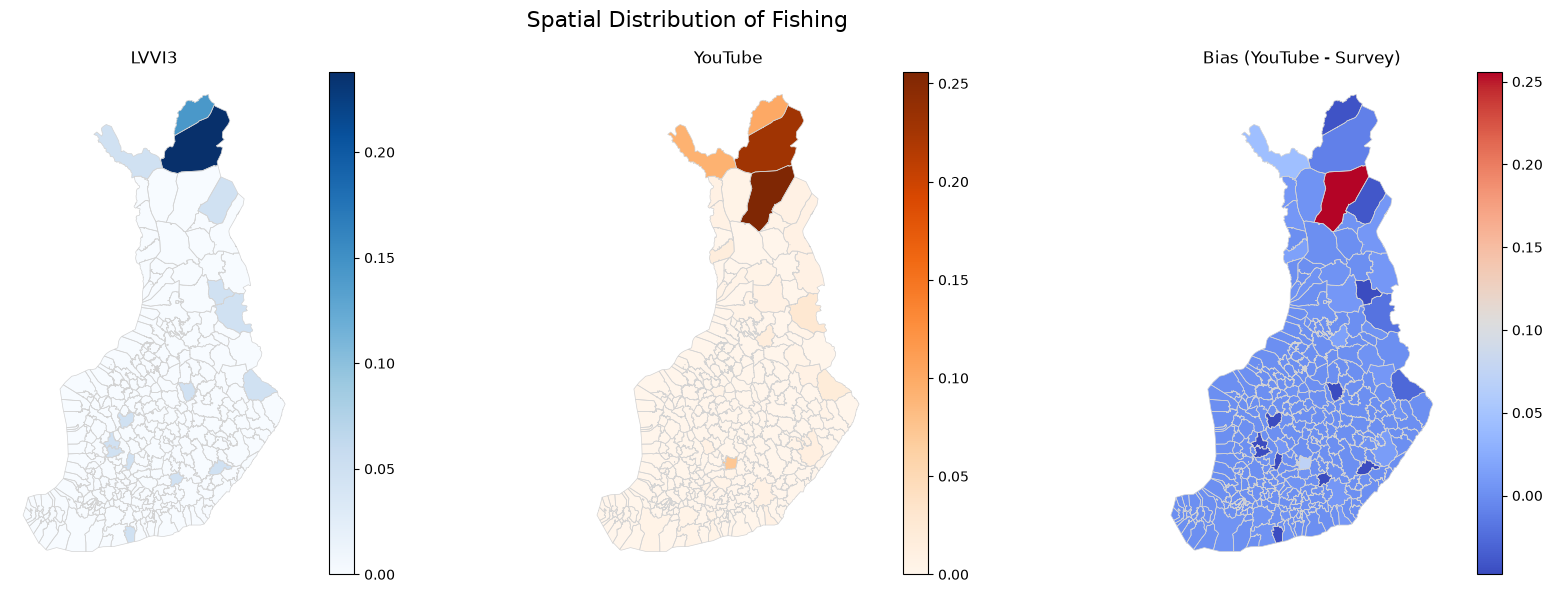

,municipality,geometry,lvvi3,youtube,diff
0,Parainen,"MULTIPOLYGON (((222641.081 6606081.869, 209305...",0.0,0.004,0.004
1,Outokumpu,"MULTIPOLYGON (((617807.354 6956270.87, 617128....",0.0,0.000,0.000
2,Rauma,"MULTIPOLYGON (((211671.977 6774130.131, 211282...",0.0,0.000,0.000
3,Alajärvi,"MULTIPOLYGON (((333911.129 6968504.391, 333550...",0.0,0.000,0.000
4,Posio,"MULTIPOLYGON (((569086.721 7303600.875, 568502...",0.0,0.000,0.000
...,...,...,...,...,...
303,Teuva,"MULTIPOLYGON (((219000.267 6933062.951, 218989...",0.0,0.000,0.000
304,Hankasalmi,"MULTIPOLYGON (((465203.294 6898115.267, 465109...",0.0,0.000,0.000
305,Soini,"MULTIPOLYGON (((365541.96 6984316.807, 365525....",0.0,0.000,0.000
306,Kauhava,"MULTIPOLYGON (((321659.111 7021930.732, 321605...",0.0,0.000,0.000


In [36]:
plot_activity_map(
    activity="Fishing",
    df_lvvi3=df_lvvi3,
    df_youtube=df_youtube,
    gdf_municipality=gdf_municipality
)

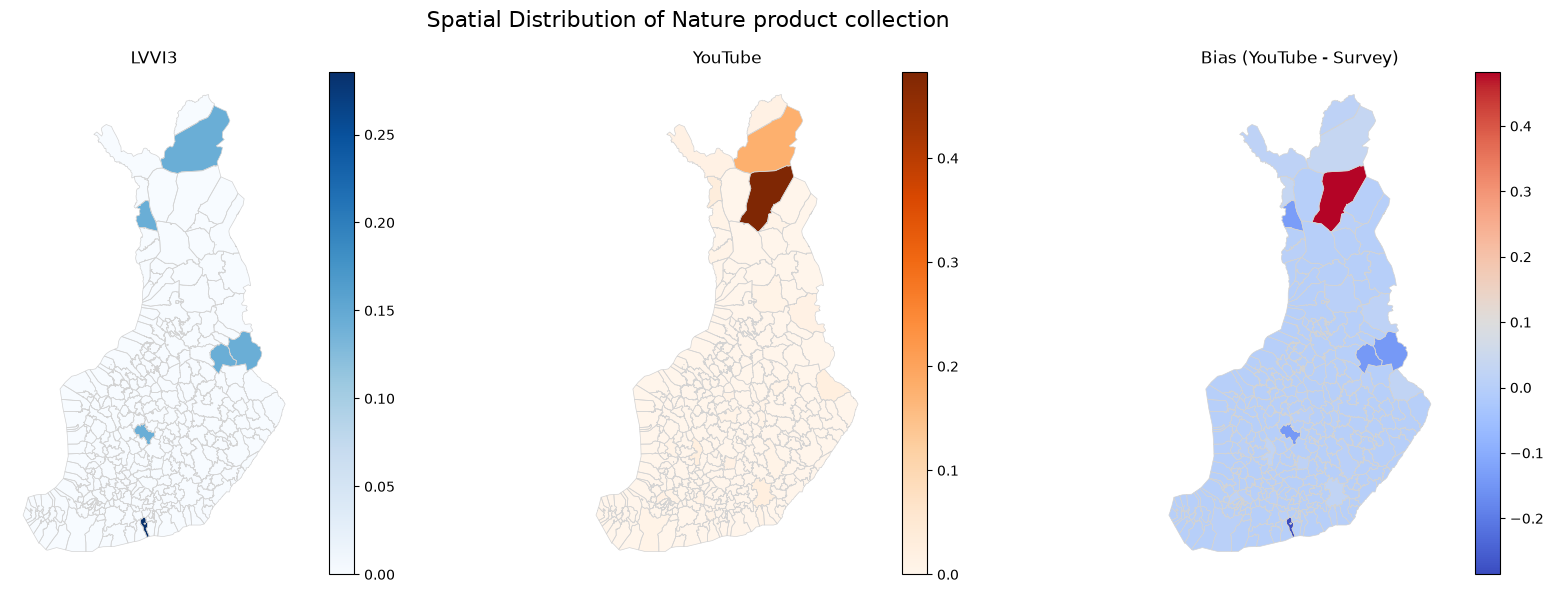

,municipality,geometry,lvvi3,youtube,diff
0,Parainen,"MULTIPOLYGON (((222641.081 6606081.869, 209305...",0.0,0.008475,0.008475
1,Outokumpu,"MULTIPOLYGON (((617807.354 6956270.87, 617128....",0.0,0.000000,0.000000
2,Rauma,"MULTIPOLYGON (((211671.977 6774130.131, 211282...",0.0,0.000000,0.000000
3,Alajärvi,"MULTIPOLYGON (((333911.129 6968504.391, 333550...",0.0,0.000000,0.000000
4,Posio,"MULTIPOLYGON (((569086.721 7303600.875, 568502...",0.0,0.000000,0.000000
...,...,...,...,...,...
303,Teuva,"MULTIPOLYGON (((219000.267 6933062.951, 218989...",0.0,0.000000,0.000000
304,Hankasalmi,"MULTIPOLYGON (((465203.294 6898115.267, 465109...",0.0,0.000000,0.000000
305,Soini,"MULTIPOLYGON (((365541.96 6984316.807, 365525....",0.0,0.000000,0.000000
306,Kauhava,"MULTIPOLYGON (((321659.111 7021930.732, 321605...",0.0,0.000000,0.000000


In [37]:
plot_activity_map(
    activity="Nature product collection",
    df_lvvi3=df_lvvi3,
    df_youtube=df_youtube,
    gdf_municipality=gdf_municipality
)

# Temporal distribution

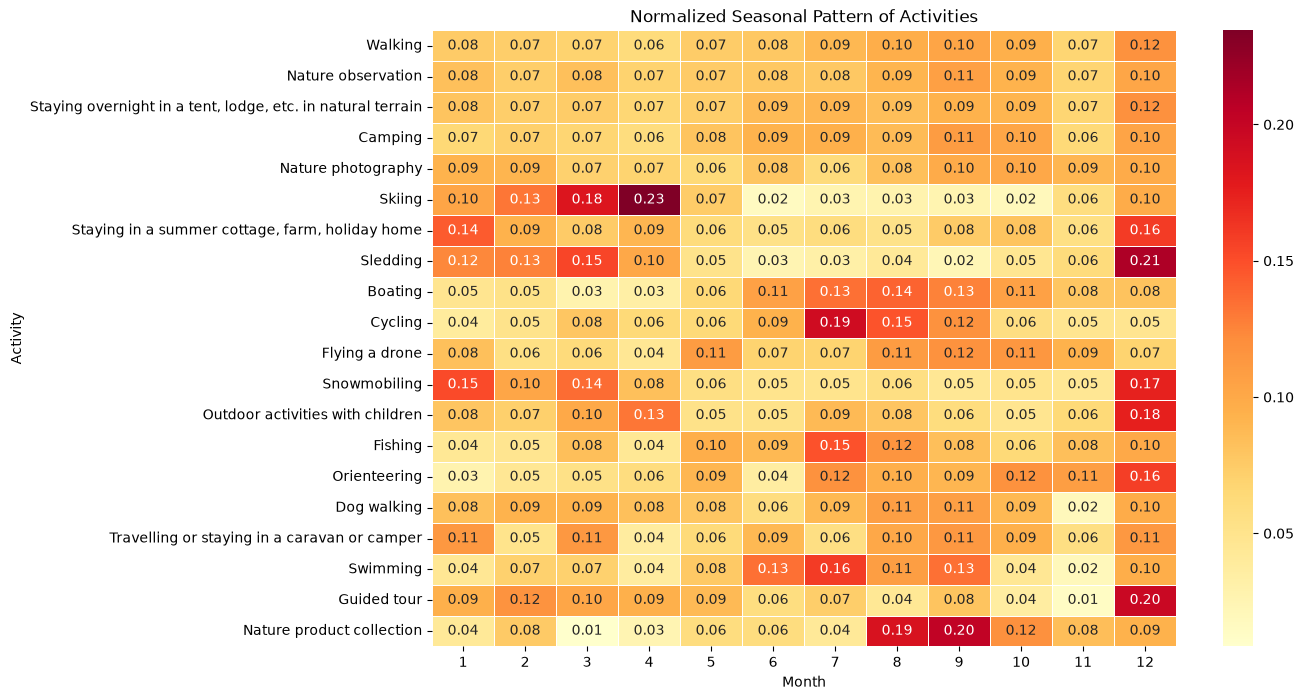

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt

top_activities = activity_counts.index
top_activities = top_activities[::-1]

# Count occurrences of each activity per month
activity_month_counts = df_youtube.groupby(['activity', 'month']).size().reset_index(name='count')
# Keep only activities in activity_counts
activity_month_counts = activity_month_counts[
    activity_month_counts['activity'].isin(activity_counts.index)
]

activity_month_counts['activity'] = pd.Categorical(
    activity_month_counts['activity'],
    categories=top_activities,
    ordered=True
)

# Pivot to activity x month
activity_month_pivot = activity_month_counts.pivot(index='activity', columns='month', values='count').fillna(0)

# Normalize per activity (row-wise)
activity_month_normalized = activity_month_pivot.div(activity_month_pivot.sum(axis=1), axis=0)

plt.figure(figsize=(12,8))
sns.heatmap(activity_month_normalized, cmap='YlOrRd', linewidths=0.5, annot=True, fmt='.2f')
plt.title('Normalized Seasonal Pattern of Activities')
plt.xlabel('Month')
plt.ylabel('Activity')
plt.show()

# Engagement metrics

In [39]:
df_engagement = df_youtube[['video_id', 'activity', 'view_count', 'like_count', 'comment_count']].copy()

In [40]:
df_engagement_agg = df_engagement[['activity', 'view_count', 'like_count', 'comment_count']].groupby('activity').sum()
df_engagement_agg.sort_values('view_count', ascending=False).head()

,view_count,like_count,comment_count
activity,,,
Walking,7975347.0,218574.0,25286.0
Fishing,6397082.0,116542.0,4846.0
"Staying overnight in a tent, lodge, etc. in natural terrain",5384278.0,137570.0,14698.0
Nature observation,5066829.0,154446.0,18703.0
Camping,4782129.0,117741.0,12403.0


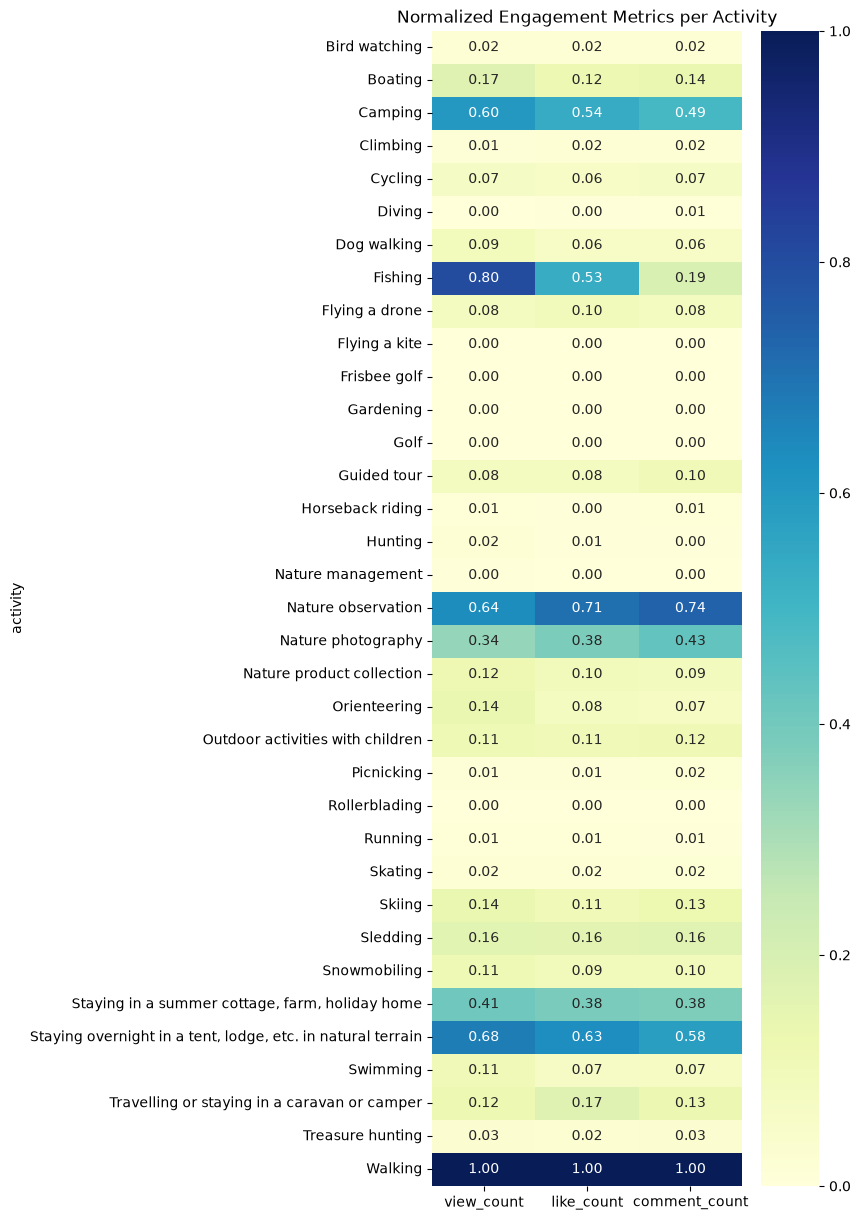

In [41]:
# Copy the dataframe
df_norm = df_engagement_agg.copy()

# Min-max normalization per column
df_norm = (df_norm - df_norm.min()) / (df_norm.max() - df_norm.min())

# Plot heatmap
plt.figure(figsize=(5,15))
sns.heatmap(df_norm, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title('Normalized Engagement Metrics per Activity')
plt.show()

# Activities in commercial forests

Videos with activity evidence in commercial forests: 1377


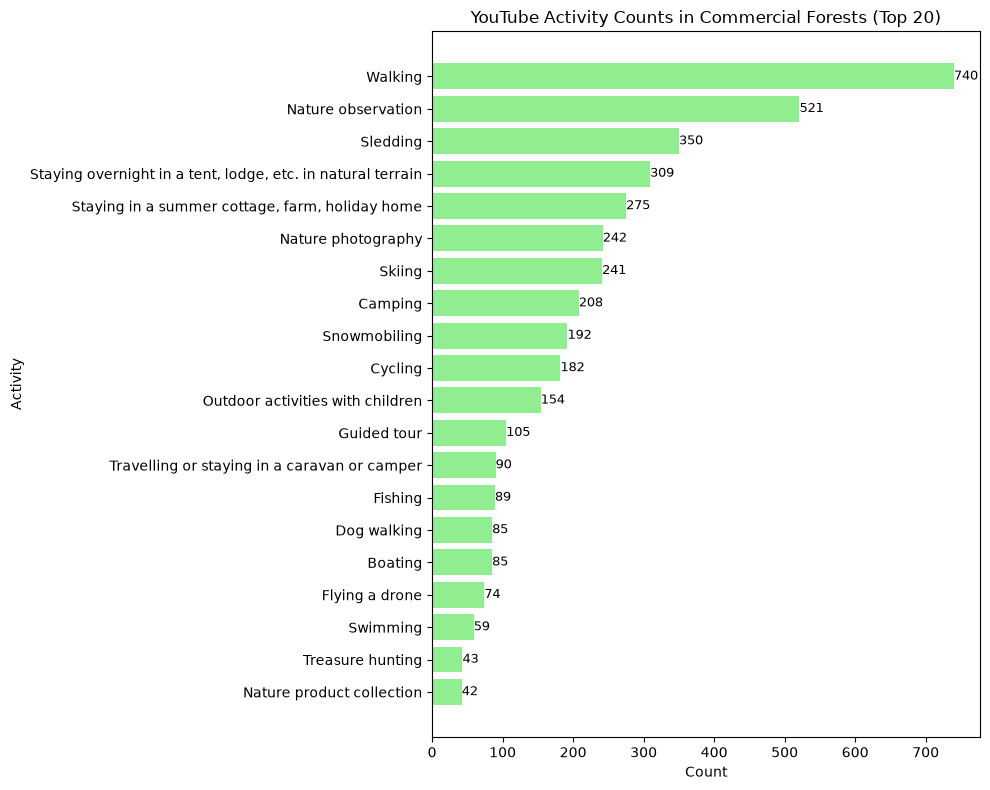

In [42]:
# Commercial forest activities, with the CORRECTED commercial-forest layer
# (Admin_level == 'Metsätalous'; see the "Area type layers" section above).
# Note: the commercial_forest flag stored in the video tables still uses the old
# subtraction definition and would overestimate.
gdf_videos_3067 = gdf_videos.to_crs(3067)
cf_poly = commercial_forest[["geometry"]].dissolve()
videos_in_cf = gpd.sjoin(
    gdf_videos_3067[["video_id", "geometry"]], cf_poly, predicate="intersects"
)["video_id"]
df_youtube_cf = df_youtube[df_youtube["video_id"].isin(videos_in_cf)]
print(f"Videos with activity evidence in commercial forests: {df_youtube_cf['video_id'].nunique()}")

# Count occurrences of each activity
activity_counts = df_youtube_cf['activity'].value_counts()
activity_counts = activity_counts[:20]
activity_counts = activity_counts[::-1]

# Plot horizontal bars
plt.figure(figsize=(10, 8))
bars = plt.barh(activity_counts.index, activity_counts.values, color='lightgreen')
plt.xlabel('Count')
plt.ylabel('Activity')
plt.title('YouTube Activity Counts in Commercial Forests (Top 20)')

# Add value labels next to bars
for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2, str(width),
             va='center', ha='left', fontsize=9)

plt.tight_layout()
plt.show()

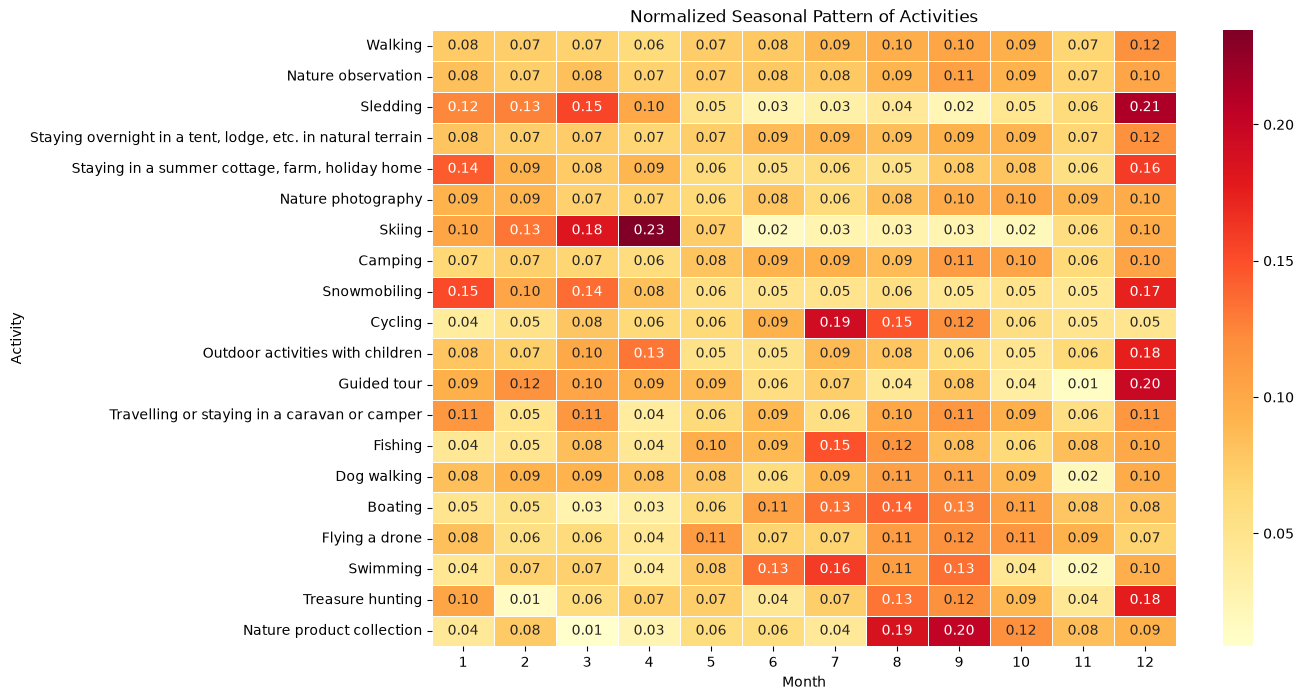

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

top_activities = activity_counts.index
top_activities = top_activities[::-1]

# Count occurrences of each activity per month
activity_month_counts = df_youtube.groupby(['activity', 'month']).size().reset_index(name='count')
# Keep only activities in activity_counts
activity_month_counts = activity_month_counts[
    activity_month_counts['activity'].isin(activity_counts.index)
]

activity_month_counts['activity'] = pd.Categorical(
    activity_month_counts['activity'],
    categories=top_activities,
    ordered=True
)

# Pivot to activity x month
activity_month_pivot = activity_month_counts.pivot(index='activity', columns='month', values='count').fillna(0)

# Normalize per activity (row-wise)
activity_month_normalized = activity_month_pivot.div(activity_month_pivot.sum(axis=1), axis=0)

plt.figure(figsize=(12,8))
sns.heatmap(activity_month_normalized, cmap='YlOrRd', linewidths=0.5, annot=True, fmt='.2f')
plt.title('Normalized Seasonal Pattern of Activities')
plt.xlabel('Month')
plt.ylabel('Activity')
plt.show()